# Classical baselines

**Final project · Intelligent museum guide** · issue #3

The director asks whether a simple classical model would do the job. Before training any network, we measure
three reference points on the shared split of `src/data.py` (1 050 train, 225 validation, 225 test images):

1. **Majority class**: the floor. With five balanced classes it is right 20 % of the time.
2. **Logistic regression on the raw pixels**: the simplest learnt model, one weight per pixel and per class.
3. **Logistic regression on colour histograms**: a classical model with hand-crafted features. A style is
   partly a palette, and a histogram does not depend on *where* the colours are in the painting.

The image size, the number of bins and the regularisation strength `C` are chosen on the **validation** set;
the **test** set is used once, at the end. Each model reports accuracy, macro-F1, the confusion matrix, the
training time and the CPU time to classify one image.

In [1]:
import sys
import time

import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

sys.path.append("..")
from src.data import load_splits
from src.train import RESULTS_DIR, classification_metrics, save_json

np.random.seed(0)
torch.manual_seed(0)
results = {}

In [2]:
def flat(splits, name):
    """Images of one split as a (N, 3 * size * size) NumPy matrix, and their labels."""
    X, y = splits[name]
    return X.reshape(len(X), -1).numpy(), y.numpy()


def time_per_image(predict_one, images, n=100):
    """Median time in milliseconds to classify ONE image, as on a kiosk (one photo at a time)."""
    times = []
    for x in images[:n]:
        start = time.perf_counter()
        predict_one(x)
        times.append(time.perf_counter() - start)
    return 1000 * float(np.median(times))

## 1. Majority class

`DummyClassifier` always predicts the most frequent training class. The classes are balanced, so it picks the
first one (Baroque) and is right on 45 test images out of 225.

In [3]:
splits, classes = load_splits("train", size=32)
X_train, y_train = flat(splits, "train")
X_test, y_test = flat(splits, "test")
majority = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results["majority"] = classification_metrics(y_test, majority.predict(X_test))
print(f"majority class: test accuracy {results['majority']['accuracy']:.3f}, "
      f"macro-F1 {results['majority']['macro_f1']:.3f}")

train 1050 images | per class {'Baroque': 210, 'Cubism': 210, 'Impressionism': 210, 'Pop_Art': 210, 'Ukiyo_e': 210}
val    225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}
test   225 images | per class {'Baroque': 45, 'Cubism': 45, 'Impressionism': 45, 'Pop_Art': 45, 'Ukiyo_e': 45}
majority class: test accuracy 0.200, macro-F1 0.067


## 2. Logistic regression on the raw pixels

The pixels are standardised with the training statistics (`load_splits("train")`). We try three image sizes
(16, 32 and 64 pixels, i.e. 768 to 12 288 inputs) and four values of `C`, the inverse of the L2 penalty
(small `C` = strong regularisation).

In [4]:
pixel_data, val_acc_pixels = {}, {}
for size in [16, 32, 64]:
    splits, _ = load_splits("train", size=size, verbose=False)
    pixel_data[size] = {name: flat(splits, name) for name in splits}
    X_tr, y_tr = pixel_data[size]["train"]
    X_va, y_va = pixel_data[size]["val"]
    for C in [1e-4, 1e-3, 1e-2, 1e-1]:
        model = LogisticRegression(C=C, max_iter=2000).fit(X_tr, y_tr)
        val_acc_pixels[(size, C)] = accuracy_score(y_va, model.predict(X_va))
        print(f"size {size:2d}  C {C:g}  train acc {model.score(X_tr, y_tr):.3f}  "
              f"val acc {val_acc_pixels[(size, C)]:.3f}")

best_size, best_C = max(val_acc_pixels, key=val_acc_pixels.get)
print(f"best on validation: size {best_size}, C {best_C:g} ({val_acc_pixels[(best_size, best_C)]:.3f})")

size 16  C 0.0001  train acc 0.410  val acc 0.356
size 16  C 0.001  train acc 0.492  val acc 0.347
size 16  C 0.01  train acc 0.614  val acc 0.324
size 16  C 0.1  train acc 0.782  val acc 0.311


size 32  C 0.0001  train acc 0.473  val acc 0.351
size 32  C 0.001  train acc 0.623  val acc 0.316


size 32  C 0.01  train acc 0.872  val acc 0.324


size 32  C 0.1  train acc 0.990  val acc 0.329


size 64  C 0.0001  train acc 0.586  val acc 0.342


size 64  C 0.001  train acc 0.854  val acc 0.329


size 64  C 0.01  train acc 0.992  val acc 0.307


size 64  C 0.1  train acc 0.999  val acc 0.280
best on validation: size 16, C 0.0001 (0.356)


**What we see.** Every configuration stays between about 0.28 and 0.36 on the validation set, whatever the
size: a weight per pixel cannot capture a style, because the same brushwork or palette can be anywhere in the
image. With a weak penalty the model learns the training set by heart (train accuracy up to 1.0) and gains
nothing on new paintings: it overfits. Note that 225 validation images give a standard error of about
3 points on an accuracy of 0.35, so the differences between these rows are mostly noise.

In [5]:
X_tr, y_tr = pixel_data[best_size]["train"]
X_te, y_te = pixel_data[best_size]["test"]
start = time.perf_counter()
pixel_model = LogisticRegression(C=best_C, max_iter=2000).fit(X_tr, y_tr)
train_time = time.perf_counter() - start

results["logreg_pixels"] = {
    **classification_metrics(y_te, pixel_model.predict(X_te)),
    "image_size": best_size,
    "C": best_C,
    "val_accuracy": val_acc_pixels[(best_size, best_C)],
    "n_params": pixel_model.coef_.size + pixel_model.intercept_.size,
    "train_time_s": train_time,
    "inference_ms_per_image": time_per_image(lambda x: pixel_model.predict(x[None]), X_te),
}
print({k: v for k, v in results["logreg_pixels"].items() if k != "confusion_matrix"})

{'accuracy': 0.3688888888888889, 'macro_f1': 0.3389596067539634, 'image_size': 16, 'C': 0.0001, 'val_accuracy': 0.35555555555555557, 'n_params': 3845, 'train_time_s': 0.012731625000014901, 'inference_ms_per_image': 0.03533298149704933}


## 3. Logistic regression on colour histograms

For each colour channel we count the fraction of pixels whose value falls in each of `bins` equal intervals
of [0, 1]. An image becomes a vector of `3 * bins` numbers, whatever its size. The features are then
standardised (`StandardScaler`, fitted on the training set inside the pipeline) before the logistic
regression. The histograms need the pixels in [0, 1], so we load the split without normalisation, at the
full 128 × 128 resolution.

In [6]:
def colour_histogram(img, bins):
    """Histogram of each channel of one (3, H, W) image in [0, 1], as fractions of the pixels: (3 * bins,)."""
    idx = (img * bins).long().clamp(0, bins - 1)          # bin of every pixel value
    counts = [torch.bincount(idx[c].flatten(), minlength=bins) for c in range(3)]
    return torch.cat(counts).float() / idx[0].numel()


def histogram_features(images, bins):
    return torch.stack([colour_histogram(img, bins) for img in images]).numpy()


raw_splits, _ = load_splits("none", size=128, verbose=False)
img_train, y_tr = raw_splits["train"]
img_val, y_va = raw_splits["val"]
img_test, y_te = raw_splits["test"]

val_acc_hist = {}
for bins in [8, 16, 32]:
    H_tr, H_va = histogram_features(img_train, bins), histogram_features(img_val, bins)
    for C in [0.01, 0.1, 1, 10]:
        model = make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)).fit(H_tr, y_tr)
        val_acc_hist[(bins, C)] = accuracy_score(y_va, model.predict(H_va))
        print(f"bins {bins:2d}  C {C:5g}  train acc {model.score(H_tr, y_tr):.3f}  "
              f"val acc {val_acc_hist[(bins, C)]:.3f}")

best_bins, best_C_hist = max(val_acc_hist, key=val_acc_hist.get)
print(f"best on validation: {best_bins} bins, C {best_C_hist:g} ({val_acc_hist[(best_bins, best_C_hist)]:.3f})")

bins  8  C  0.01  train acc 0.416  val acc 0.400
bins  8  C   0.1  train acc 0.438  val acc 0.436
bins  8  C     1  train acc 0.441  val acc 0.440
bins  8  C    10  train acc 0.443  val acc 0.427


bins 16  C  0.01  train acc 0.449  val acc 0.409
bins 16  C   0.1  train acc 0.463  val acc 0.418
bins 16  C     1  train acc 0.469  val acc 0.387
bins 16  C    10  train acc 0.470  val acc 0.387


bins 32  C  0.01  train acc 0.481  val acc 0.400
bins 32  C   0.1  train acc 0.508  val acc 0.378
bins 32  C     1  train acc 0.513  val acc 0.360
bins 32  C    10  train acc 0.524  val acc 0.356
best on validation: 8 bins, C 1 (0.440)


In [7]:
start = time.perf_counter()
H_tr = histogram_features(img_train, best_bins)
hist_model = make_pipeline(StandardScaler(), LogisticRegression(C=best_C_hist, max_iter=5000)).fit(H_tr, y_tr)
train_time = time.perf_counter() - start


def predict_histogram(img):
    return hist_model.predict(colour_histogram(img, best_bins)[None].numpy())


logreg = hist_model[-1]
results["logreg_histograms"] = {
    **classification_metrics(y_te, hist_model.predict(histogram_features(img_test, best_bins))),
    "bins": best_bins,
    "C": best_C_hist,
    "val_accuracy": val_acc_hist[(best_bins, best_C_hist)],
    "n_params": logreg.coef_.size + logreg.intercept_.size,
    "train_time_s": train_time,
    "inference_ms_per_image": time_per_image(predict_histogram, img_test),   # histogram + prediction
}
print({k: v for k, v in results["logreg_histograms"].items() if k != "confusion_matrix"})

{'accuracy': 0.39555555555555555, 'macro_f1': 0.3797126371137675, 'bins': 8, 'C': 1, 'val_accuracy': 0.44, 'n_params': 125, 'train_time_s': 0.2325884171295911, 'inference_ms_per_image': 0.33954193349927664}


## 4. Comparison on the test set

model              accuracy macro-F1  params train (s) ms/image
majority              0.200    0.067       0      0.00    0.000
logreg_pixels         0.369    0.339    3845      0.01    0.035
logreg_histograms     0.396    0.380     125      0.23    0.340


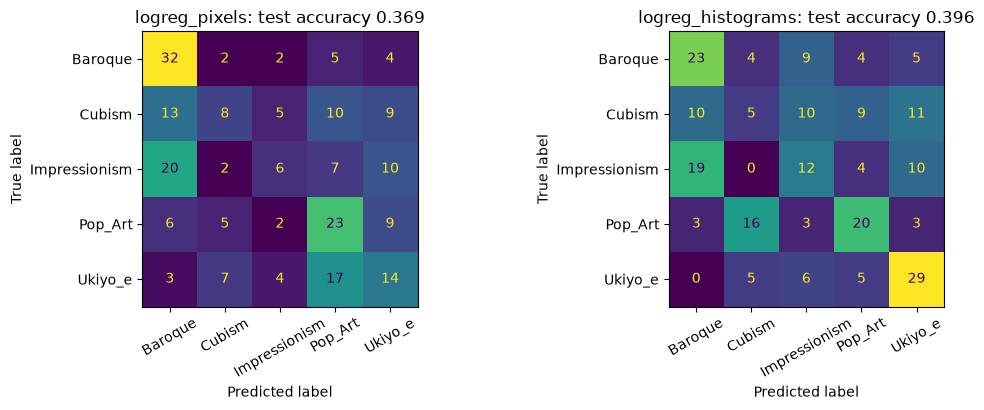

In [8]:
print(f"{'model':18s} {'accuracy':>8s} {'macro-F1':>8s} {'params':>7s} {'train (s)':>9s} {'ms/image':>8s}")
for name, r in results.items():
    print(f"{name:18s} {r['accuracy']:8.3f} {r['macro_f1']:8.3f} {r.get('n_params', 0):7d} "
          f"{r.get('train_time_s', 0):9.2f} {r.get('inference_ms_per_image', 0):8.3f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, name in zip(axes, ["logreg_pixels", "logreg_histograms"]):
    ConfusionMatrixDisplay(np.array(results[name]["confusion_matrix"]), display_labels=classes).plot(
        ax=ax, colorbar=False)
    ax.set_title(f"{name}: test accuracy {results[name]['accuracy']:.3f}")
    ax.tick_params(axis="x", labelrotation=30)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "baseline_confusion.png", dpi=120)
plt.show()

save_json(results, RESULTS_DIR / "baseline.json")

## What we take from it

- **The floor is 0.20** (macro-F1 0.07): any model must beat that to be useful.
- **Raw pixels reach 0.37** on the test set. The confusion matrix shows what the model really uses: overall
  brightness. Dark paintings are called Baroque (32 / 45 Baroque, but also 20 / 45 Impressionist works), and
  Cubism is almost never recognised (8 / 45).
- **Colour histograms reach 0.40** (0.44 on validation) with only 125 weights. Ukiyo-e, with its paper tones
  and flat colours, is the best recognised style (29 / 45). Colour alone cannot see brushwork or geometry,
  though: Impressionism is still taken for Baroque (19 / 45) and Cubism is spread over every class (5 / 45).
- **Both are almost free**: under a second of training and under 0.4 ms per image on one CPU core, which fits
  any kiosk. But they are wrong about 6 times out of 10, which would not be acceptable for a visitor.

The question for the neural networks is therefore not whether they run on a kiosk, but **how many points of
accuracy they add, and at what CPU cost**. On 225 test images the standard error is about 3 points, so only
gaps larger than that should be trusted.
